# A battery on your own scored sample: contract 1, run_suite and the lights

**Question:** If you bring a scored sample of your own, does a battery of the engine's tests, run under one policy, find the sample whose PDs are too low and leave the calibrated one alone, and which tests carry the finding?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- put a CSV of scored obligors through contract 1 and read what it accepts, flags and rejects, and why it never coerces a value;
- map PDs to the master scale and build the grade table the grade-level tests read;
- assemble a battery of engine tests and run it under one policy with `run_suite`, which never stops at the first failure;
- open three of the tests (the PSI, Hosmer-Lemeshow and the chi-square over grades) and say what each one's degrees of freedom and benchmark are;
- explain why the level tests and the stability test are red on the current sample while the ranking test stays green.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

This notebook also imports two readers of the product's pipeline: contract 1 (`pipeline.io.contract`) and the master scale (`pipeline.core.calibration`). The pipeline is plain scripts and not a package, so the notebook puts `data-pipeline/` on the import path and imports them from there: one reader for the pipeline, the tests and these notebooks, never a copy. The next cell does it and prints the versions.

In [1]:
# Put the pipeline on the import path, import the readers and the engine, and print the package versions
import importlib.metadata as md
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.core.suite import run_suite
from riskvalidation.validation import calibration as cal
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import stability as st

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.core.calibration import GRADES, MASTER_SCALE_UPPER, grade_table
from pipeline.io import contract
from pipeline.io.formats import read_csv_rows

for name in ("riskvalidation", "numpy", "matplotlib", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2
pandas 3.0.6


## Data

The same two synthetic samples with a known truth as in notebook 03, committed in `data/examples/` (owner: this repository; no third-party licence, MIT; generated from a seed by `data-pipeline/pipeline/io/examples.py`):

- `scored_sample_development.csv`: 2,000 obligors on 2024-12-31, PDs calibrated by construction. It plays the part of the **development sample**, the reference a validator compares against.
- `scored_sample_current.csv`: 2,000 obligors on 2025-12-31 from a riskier population whose defaults arrive at 1.5 times the PD. It is the **sample under validation**.

Your own model enters the same way: a CSV with `id`, `observation_date`, `target` and `pd`, one row per obligor. The shape is the `scored_sample` family of contract 1 (`docs/guides/02_validate-your-own-model.md`). Both files are read below, through contract 1, in step 2.

## Method

The route of a model you bring to Contraste has five stations: the contract that decides which rows may enter, the master scale that groups obligors into grades, the battery of tests that reads the sample, the policy that colours the results, and the table of lights a validator reads. We walk it on the two samples and open three tests on the way to see what their lights are made of.

### Step 1: contract 1 reads, flags and rejects, and never coerces

Contract 1 parses every value by its declared kind. A PD of 1.2, a target of `yes` or a second row with the same identifier on the same date is **rejected**, with the field, the value and what was expected; a value that is odd but usable is **flagged**; a column the family does not declare is listed as **ignored** and never used. Nothing is silently repaired, because a repaired value is a number the validator did not see. The next cell shows the rule on five rows written by hand, three of them wrong.

In [2]:
# Five rows written by hand: two valid, three that contract 1 must reject (a PD of 1.2, a target "yes", a repeated id)
KIND = {"rejected": "rejected", "flagged": "flagged"}
planted = [
    {"id": "A1", "observation_date": "2025-12-31", "target": "0", "pd": "0.05", "segment": "retail"},
    {"id": "A2", "observation_date": "2025-12-31", "target": "1", "pd": "1.2", "segment": "retail"},
    {"id": "A3", "observation_date": "2025-12-31", "target": "yes", "pd": "0.30", "segment": "retail"},
    {"id": "A1", "observation_date": "2025-12-31", "target": "1", "pd": "0.10", "segment": "retail"},
    {"id": "A5", "observation_date": "2025-12-31", "target": "1", "pd": "0.20", "segment": "retail", "extra": "x"},
]
report = contract.validate("scored_sample", planted)
counts = report.counts()
print("contract 1 on the five rows:", counts["input"], "read,", counts["accepted"], "accepted")
print(counts["rejected"], "rejected,", counts["flagged"], "flagged")
print("ignored columns:", report.ignored_columns)
shown = [
    {"verdict": KIND[e["kind"]], "row": e["row"], "field": e["field"], "value": e["value"]}
    for e in report.examples()
]
pd.DataFrame(shown)

contract 1 on the five rows: 5 read, 2 accepted
3 rejected, 0 flagged
ignored columns: ['extra']


,verdict,row,field,value
0,rejected,1,pd,1.2
1,rejected,2,target,yes
2,rejected,3,id,A1


Contract 1 rejected exactly the three planted errors, each with its row, field and value: the PD of 1.2 (out of range for a probability), the target `yes` (not 0 or 1) and the repeated identifier `A1` on the same date. It accepted the other two rows and listed `extra` as an ignored column. The table names what is wrong and where, and the rule behind each verdict is in the contract's own text. It does not show what the contract does with a value that is only odd; that is the `flagged` count, zero here.

### Step 2: the two real files

`read_csv_rows` reads the text without interpreting it, `contract.validate` applies the family, and the arrays the battery needs come from the **accepted** records only. The next cell does it for both files and prints what contract 1 decided.

In [3]:
# Read both files through contract 1 and keep the accepted records as arrays: PDs first, outcomes second
samples = {}
rows_table = []
for name in ("development", "current"):
    rows = read_csv_rows(ROOT / "data" / "examples" / f"scored_sample_{name}.csv")
    checked = contract.validate("scored_sample", rows)
    counts = checked.counts()
    pd_values = np.array([r["pd"] for r in checked.accepted])
    samples[name] = (pd_values, np.array([r["target"] for r in checked.accepted]))
    rows_table.append(
        {
            "file": f"scored_sample_{name}.csv",
            "read": counts["input"],
            "accepted": counts["accepted"],
            "rejected": counts["rejected"],
            "flagged": counts["flagged"],
        }
    )
pd_dev, y_dev = samples["development"]
pd_cur, y_cur = samples["current"]
pd.DataFrame(rows_table)

,file,read,accepted,rejected,flagged
0,scored_sample_development.csv,2000,2000,0,0
1,scored_sample_current.csv,2000,2000,0,0


Both files pass whole: 2,000 rows read and 2,000 accepted each, with nothing rejected or flagged, so the arrays below hold every obligor. A file with errors would have come back with fewer accepted rows and the reasons, and the validator would have to decide what to do before any test ran. The notebook never drops a row on its own.

### Step 3: the master scale and the grade table

Rating-style tests do not read one PD per obligor. They read **grades**, groups of obligors with similar risk, each with its count, its defaults and its mean PD. Contraste maps PDs to a geometric master scale: upper bounds of 1% times 1.5 to the power k for k = 0 to 10, then 100%, twelve grades in all. The next cell prints the scale and builds the grade table of the current sample, with the empty grades dropped.

In [4]:
# Map the current sample to the master scale and print the non-empty grades
print("grades of the master scale:", len(GRADES))
print("first upper bounds:", [round(b, 4) for b in MASTER_SCALE_UPPER[:4]])
table = [g for g in grade_table(pd_cur, y_cur) if g["n"] > 0]
grades = pd.DataFrame(table)[["grade", "hi", "n", "d", "pd", "dr"]].round(4)
names = ["grade", "upper bound", "obligors", "defaults", "mean PD", "rate"]
grades.columns = names
grades

grades of the master scale: 12
first upper bounds: [0.01, 0.015, 0.0225, 0.0338]


,grade,upper bound,obligors,defaults,mean PD,rate
0,G01,0.0100,189,1,0.0052,0.0053
1,G02,0.0150,115,1,0.0125,0.0087
2,G03,0.0225,155,3,0.0188,0.0194
3,G04,0.0338,207,6,0.0278,0.0290
4,G05,0.0506,290,22,0.0419,0.0759
5,G06,0.0759,352,25,0.0626,0.0710
6,G07,0.1139,317,48,0.0926,0.1514
7,G08,0.1709,233,49,0.1388,0.2103
8,G09,0.2563,121,43,0.2039,0.3554
9,G10,0.3844,20,9,0.3002,0.4500


Twelve grades exist and eleven are occupied: G12 is empty, and G11 holds a single obligor. Look at the rate column against the mean PD: in the first four grades the observed rate follows the PD (0.0053 against 0.0052 in G01, 0.0290 against 0.0278 in G04), and from G05 on it runs ahead (0.0759 against 0.0419 in G05, 0.3554 against 0.2039 in G09). The table is the raw material of the grade-level tests and already hints at the finding, but a table of rates cannot say whether the gap is more than chance; the tests do.

### Step 4: the tasks of a battery

A battery is a list of tasks, each a pair of an engine test and its arguments, and `run_suite` runs them in order under one policy. The tasks of a PD validation are these:

| Test | What it asks | Reference |
|---|---|---|
| `disc.auc` | does the PD rank defaulters above non-defaulters? | ECB 2019, Annex 1 (section 3.1) |
| `disc.auc_vs_initial` | has the ranking deteriorated since development (one-sided)? | ECB 2019, section 2.5.4.1 |
| `pd.jeffreys`, `pd.binomial` | is the portfolio PD too low? | ECB 2019; BCBS WP14 |
| `pd.binomial_vasicek` | the same, allowing for a one-factor default correlation (rho = 0.04, the Basel retail revolving value) | BCBS WP14 |
| `pd.chi2_grades` | do the defaults of all grades match their PDs? | BCBS WP14 |
| `pd.hosmer_lemeshow`, `pd.spiegelhalter` | do the obligor-level PDs match the outcomes? | Hosmer and Lemeshow 1980; Spiegelhalter 1986 |
| `stability.psi` | has the PD distribution moved since development? | Yurdakul and Naranjo 2020 |

Seven tasks need only the sample. The next cell lists them for each sample, with the inputs each one reads: the totals of the portfolio, the grades, or the obligor-level arrays.

In [5]:
# One battery per sample: a list of (engine test, arguments) pairs; the engine computes every statistic when it runs
RHO = 0.04
NAMES = {"development": "development", "current": "current"}
batteries = {}
for name, (pd_s, y_s) in samples.items():
    grades_s = [g for g in grade_table(pd_s, y_s) if g["n"] > 0]
    level = dict(n=len(y_s), d=int(y_s.sum()), pd=float(pd_s.mean()))
    grade_args = dict(n=[g["n"] for g in grades_s], d=[g["d"] for g in grades_s], pd=[g["pd"] for g in grades_s])
    batteries[name] = [
        (disc.disc_auc, dict(risk=pd_s, defaults=y_s)),
        (cal.pd_jeffreys, level),
        (cal.pd_binomial, level),
        (cal.pd_binomial_vasicek, dict(**level, rho=RHO)),
        (cal.pd_chi2_grades, grade_args),
        (cal.pd_hosmer_lemeshow, dict(defaults=y_s, pd=pd_s, fitted=False)),
        (cal.pd_spiegelhalter, dict(defaults=y_s, pd=pd_s)),
    ]
print("tasks of the battery:", [func.__name__ for func, _ in batteries["development"]])

tasks of the battery: ['disc_auc', 'pd_jeffreys', 'pd_binomial', 'pd_binomial_vasicek', 'pd_chi2_grades', 'pd_hosmer_lemeshow', 'pd_spiegelhalter']


The seven tasks are built for both samples, and the engine has not computed anything yet: a task is only a function and its arguments. Two tests compare the sample with the development and need a reference: the AUC against the initial one, which carries the development AUC's own variance because ignoring it makes the test reject more often than its level when nothing has changed, and the PSI, whose ten bins are the deciles of the development PDs, fixed before the current sample is seen. The next cell computes those two inputs with the engine and joins the two tasks to the current battery only, because the development sample would be compared with itself.

In [6]:
# With the development sample as the reference, two tasks join the current battery: the AUC against it and the PSI
auc_ref, variance_ref, *_ = disc.auc_with_variance(pd_dev, y_dev)
edges = st.quantile_edges(pd_dev, 10)
reference_tasks = [
    (disc.disc_auc_vs_initial, dict(auc_initial=float(auc_ref), risk=pd_cur, defaults=y_cur,
                                    auc_initial_variance=float(variance_ref))),
    (st.stability_psi, dict(expected_counts=st.bin_counts(pd_dev, edges), actual_counts=st.bin_counts(pd_cur, edges))),
]
batteries["current"] = batteries["current"] + reference_tasks
print("tasks of the current battery with the reference:", [func.__name__ for func, _ in batteries["current"]])

tasks of the current battery with the reference: ['disc_auc', 'pd_jeffreys', 'pd_binomial', 'pd_binomial_vasicek', 'pd_chi2_grades', 'pd_hosmer_lemeshow', 'pd_spiegelhalter', 'disc_auc_vs_initial', 'stability_psi']


The current battery has nine tasks and the development battery seven. Two choices in the arguments deserve a remark. `fitted=False` tells Hosmer-Lemeshow that the PDs were given before the outcomes, so it uses as many degrees of freedom as groups, where a model fitted on the sample would lose two. And `rho = 0.04` in the Vasicek-adjusted binomial is the asset correlation of the Basel retail revolving exposures, an assumption written in the task and not one the data support.

### Step 5: run the batteries

`run_suite` takes the tasks, the policy and the identifiers, runs every task, and returns a `SuiteRun` with one `TestResult` per task. The next cell runs both batteries under the default policy, prints the counts of lights and the worst light of each, and the AUC of each sample.

In [7]:
# Run each battery under the default policy; run_suite gives every result the same model identifier and segment
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated", "error": "error"}
policy = default_policy()
suites = {
    name: run_suite(tasks, policy=policy, model_id=name, segment="portfolio")
    for name, tasks in batteries.items()
}
by_test = {name: {r.test_id: r for r in suite.results} for name, suite in suites.items()}
print("policy:", suites["current"].policy_version)
for name, suite in suites.items():
    shown = {LIGHT[key]: value for key, value in suite.counts().items() if value}
    print(f"{NAMES[name]}: counts: {shown} | worst light: {LIGHT[suite.worst().value]}")
    print(f"    AUC: {by_test[name]['disc.auc'].metric:.3f}")

policy: riskvalidation-default 2026.10.1
development: counts: {'green': 6, 'not evaluated': 1} | worst light: green
    AUC: 0.743
current: counts: {'green': 2, 'red': 6, 'not evaluated': 1} | worst light: red
    AUC: 0.779


The development sample comes out with six green results and one not evaluated, and its worst light is green. The current sample has six red results, two green and one not evaluated, so its worst light is red. The one result without a colour in each is the AUC, which the default policy leaves uncoloured, as notebook 02 saw. The AUC itself is 0.743 on the development sample and 0.779 on the current one: the ranking did not get worse. The counts say the battery separates the two samples; the table below says which tests do it.

### Step 6: the table of lights

The next cell lines up, for every test, the p-value and the light on both samples. A dash is a test that was not run on that sample or a result with no p-value.

In [8]:
# The table of lights: for each test, the p-value and the light on both samples
lights = []
for test_id in by_test["current"]:
    row = {"test": test_id}
    for name in suites:
        result = by_test[name].get(test_id)
        p_text = "-" if result is None or result.p_value is None else f"{result.p_value:.3g}"
        row[f"p-value ({NAMES[name]})"] = p_text
        row[f"light ({NAMES[name]})"] = "-" if result is None else LIGHT[result.light.value]
    lights.append(row)
pd.DataFrame(lights)

,test,p-value (development),light (development),p-value (current),light (current)
0,disc.auc,-,not evaluated,-,not evaluated
1,pd.jeffreys,0.863,green,6.05e-09,red
2,pd.binomial,0.874,green,7.59e-09,red
3,pd.binomial_vasicek,0.54,green,0.114,green
4,pd.chi2_grades,0.509,green,2.65e-07,red
5,pd.hosmer_lemeshow,0.687,green,3.87e-09,red
6,pd.spiegelhalter,0.831,green,3.64e-09,red
7,disc.auc_vs_initial,-,-,0.914,green
8,stability.psi,-,-,4.21e-10,red


On the development sample every p-value is far from the cut points, between 0.509 and 0.874, and every light is green. On the current sample the Jeffreys test (6.05e-09), the binomial test (7.59e-09), the chi-square over grades (2.65e-07), Hosmer-Lemeshow (3.87e-09), Spiegelhalter (3.64e-09) and the PSI (4.21e-10) are red. Two tests stay green: the AUC against the initial one, with a p-value of 0.914, and the Vasicek-adjusted binomial, with 0.114. The first is the ranking, which is intact. The second is the instructive miss, discussed after the figure. The next cell draws the table as evidence.

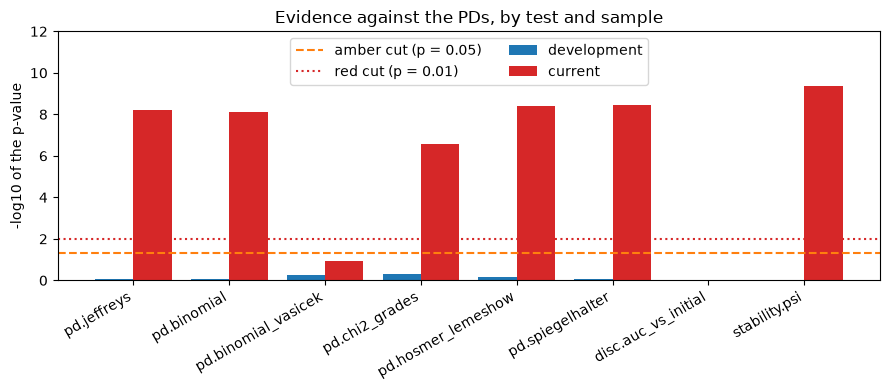

In [9]:
# Draw the evidence of each test against the PDs as -log10 of its p-value, for both samples
tests = [t for t, r in by_test["current"].items() if r.p_value is not None]
positions = np.arange(len(tests))
fig, ax = plt.subplots(figsize=(9, 4))
for shift, name, colour in ((-0.2, "development", "tab:blue"), (0.2, "current", "tab:red")):
    p_values = [by_test[name][t].p_value if t in by_test[name] else 1.0 for t in tests]
    ax.bar(positions + shift, -np.log10(np.clip(p_values, 1e-300, 1)), width=0.4, color=colour, label=NAMES[name])
ax.axhline(-np.log10(0.05), color="tab:orange", linestyle="--", label="amber cut (p = 0.05)")
ax.axhline(2, color="tab:red", linestyle=":", label="red cut (p = 0.01)")
ax.set_xticks(positions)
ax.set_xticklabels(tests, rotation=30, ha="right")
ax.set_ylim(0, 12)
ax.set_ylabel("-log10 of the p-value")
ax.set_title("Evidence against the PDs, by test and sample")
ax.legend(ncol=2, loc="upper center")
fig.tight_layout()
plt.show()

Each bar is the strength of the evidence against the PDs, minus the base-10 logarithm of the p-value, so a taller bar is a smaller p-value; the dashed and dotted lines are the amber (p = 0.05) and red (p = 0.01) cuts. The development bars barely rise from zero, and the current bars for the level and fit tests reach between 6.6 and 8.4 and the PSI about 9.4, far above the red cut. The Vasicek-adjusted bar is the only level test below the red line, near 1. The figure shows evidence, not size: a tall bar says the PDs are too low with confidence, not by how much, and the two reference tests have no development bar because they compare against it.

The Vasicek miss is worth a sentence. With an asset correlation of 0.04 the excess of defaults of one period is compatible with a systematic factor that moved the whole portfolio, and one period cannot tell the two apart. The tests that assume independent defaults are the more sensitive; here the truth is independent defaults at 1.5 times the PD, so the Vasicek green is a miss, the price of allowing for correlation being power.

### Step 7: the PSI, opened

The PSI compares the share of each sample in $B$ bins fixed on the development sample. With $E_i$ and $A_i$ the counts of the development and the current sample in bin $i$, $n = \sum_i E_i$, $m = \sum_i A_i$, $e_i = E_i / n$ and $a_i = A_i / m$:

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

An empty bin is floored at half an observation so that the logarithm stays finite. The usual reading is a rule of thumb, 0.10 and 0.25, used without reference to error rates. Yurdakul and Naranjo (2020) show that, scaled by the two sample sizes, the PSI follows a chi-square distribution with $B - 1$ degrees of freedom when nothing changed:

$$\left(\frac{1}{n} + \frac{1}{m}\right)^{-1}\mathrm{PSI} \;\approx\; \chi^2_{B-1}$$

which gives a p-value from the upper tail and the critical PSI at level $\alpha$:

$$\mathrm{PSI}_{\mathrm{crit}} = \left(\frac{1}{n} + \frac{1}{m}\right)\chi^2_{1-\alpha,\,B-1}$$

The engine's light follows that p-value. The next cell reads the PSI result of the current battery and asks the engine for the critical PSI at 5% with `psi_benchmark`.

In [10]:
# The PSI row of the current battery, its scale and the critical PSI the engine derives for these sample sizes
psi = by_test["current"]["stability.psi"]
n_dev, n_cur = psi.extras["n"], psi.extras["m"]
critical = st.psi_benchmark(n_dev, n_cur, bins=psi.extras["bins"], alpha=0.05)
scale = 1 / n_dev + 1 / n_cur
print("obligors per sample:", n_dev, "/", n_cur, "| bins:", psi.extras["bins"])
print("scale 1/n + 1/m:", scale)
print("PSI:", round(psi.metric, 4), "| scaled statistic:", round(psi.metric / scale, 3))
print("degrees of freedom:", psi.extras["bins"] - 1, "| p-value:", format(psi.p_value, ".3g"))
print("critical PSI at 5%:", round(critical, 4))
print("contribution per bin:", [round(c, 4) for c in psi.extras["contributions"]])

obligors per sample: 2000 / 2000 | bins: 10
scale 1/n + 1/m: 0.001
PSI: 0.0626 | scaled statistic: 62.603
degrees of freedom: 9 | p-value: 4.21e-10
critical PSI at 5%: 0.0169
contribution per bin: [0.0123, 0.0015, 0.0066, 0.0028, 0.0, 0.0, 0.0003, 0.0007, 0.0008, 0.0376]


The PSI of the current sample is 0.0626, which scaled by $(1/2000 + 1/2000)^{-1}$ is 62.603 on 9 degrees of freedom: a p-value of 4.21e-10. The critical PSI at 5% for these sample sizes is 0.0169, so 0.0626 is nearly four times the value that separates chance from change. The conventional reading calls it little change, because it is below 0.10; the chi-square benchmark disagrees, and with 2,000 obligors per sample it is the one with a known error rate. The contributions list shows where the shift is: bin 10 alone contributes 0.0376 of the 0.0626, and bins 1 and 3 add 0.0123 and 0.0066. The next cell draws the two samples' shares per bin and the contributions.

development obligors per bin: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
current obligors per bin:     [136, 176, 152, 168, 200, 202, 190, 217, 218, 341]


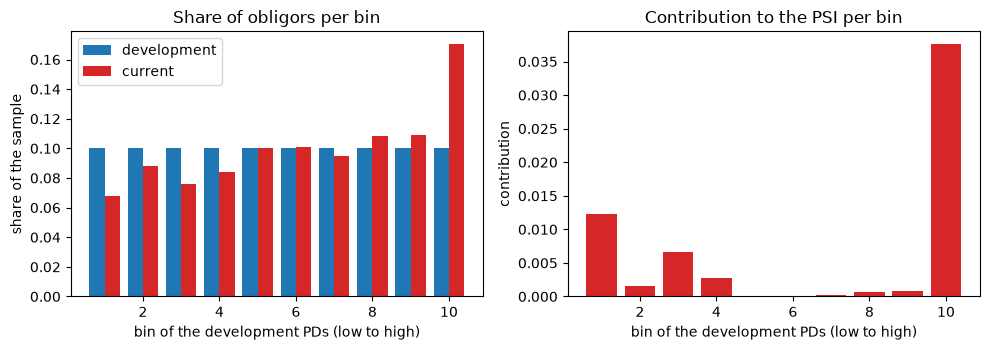

In [11]:
# Draw the share of each sample in the ten bins of the development PDs, and the contribution of each bin to the PSI
counts_dev = st.bin_counts(pd_dev, edges)
counts_cur = st.bin_counts(pd_cur, edges)
print("development obligors per bin:", counts_dev.tolist())
print("current obligors per bin:    ", counts_cur.tolist())
share_dev = counts_dev / len(pd_dev)
share_cur = counts_cur / len(pd_cur)
bins = np.arange(1, len(share_dev) + 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(bins - 0.2, share_dev, width=0.4, color="tab:blue", label=NAMES["development"])
left.bar(bins + 0.2, share_cur, width=0.4, color="tab:red", label=NAMES["current"])
left.set_xlabel("bin of the development PDs (low to high)")
left.set_ylabel("share of the sample")
left.set_title("Share of obligors per bin")
left.legend()
right.bar(bins, psi.extras["contributions"], color="tab:red")
right.set_xlabel("bin of the development PDs (low to high)")
right.set_ylabel("contribution")
right.set_title("Contribution to the PSI per bin")
fig.tight_layout()
plt.show()

The development sample has 200 of its 2,000 obligors, 10%, in every bin by construction, and the current sample drifts away from that flat profile: it has 136 obligors in bin 1 (7%) and 341 in the top bin (17%). The population moved toward higher PDs, and the right panel shows that the top bin carries most of the PSI. That is a shift of the distribution, which the PSI sees without any outcome; the level tests see the outcomes. The figure does not say whether the shift is the cause of the excess defaults, only that both happened together.

### Step 8: Hosmer-Lemeshow, opened

The Hosmer-Lemeshow test (Hosmer and Lemeshow, 1980) sorts the obligors by PD, cuts them into $G$ groups of equal size and compares, in each group $g$, the observed defaults $O_g$ with the expected defaults $E_g$, the sum of the PDs of its $m_g$ obligors:

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

The reference distribution is chi-square, and its degrees of freedom depend on where the PDs came from: $G$ for PDs given before the outcomes, $G - 2$ for PDs fitted on these same observations. A validation sample is the first case, which is why the battery set `fitted=False` and the engine used $G = 10$. The next cell reads the statistic from the suite and recomputes the test under the other rule, to see how much the rule matters.

In [12]:
# Hosmer-Lemeshow on the current sample read under the two rules: PDs given beforehand, and PDs fitted on the sample
rows = []
for label, fitted in (("PDs given beforehand", False), ("PDs fitted on this sample", True)):
    result = cal.pd_hosmer_lemeshow(defaults=y_cur, pd=pd_cur, fitted=fitted, policy=policy, model_id="current")
    rows.append({"reading": label, "degrees of freedom": result.extras["dof"], "p-value": f"{result.p_value:.3g}",
                 "light": LIGHT[result.light.value]})
hl = by_test["current"]["pd.hosmer_lemeshow"]
print("Hosmer-Lemeshow statistic:", round(hl.statistic, 2), "| groups:", hl.extras["groups"])
pd.DataFrame(rows)

Hosmer-Lemeshow statistic: 59.85 | groups: 10


,reading,degrees of freedom,p-value,light
0,PDs given beforehand,10,3.87e-09,red
1,PDs fitted on this sample,8,4.99e-10,red


The statistic is 59.85 over 10 groups. Read with 10 degrees of freedom, the right rule for a validation sample, the p-value is 3.87e-09; had the PDs been fitted on this sample, the engine would use 8 degrees of freedom and the p-value would be 4.99e-10. Both are red, so here the rule does not change the conclusion, but on a borderline sample it could, which is why the engine makes the choice an explicit argument instead of a default hidden inside the test.

### Step 9: the chi-square over grades, opened

The test over grades (BCBS Working Paper 14) takes the $K$ non-empty grades of the master scale, with $n_i$ obligors, $d_i$ defaults and mean PD $p_i$ in grade $i$:

$$T = \sum_{i=1}^{K} \frac{(n_i p_i - d_i)^2}{n_i\,p_i\,(1 - p_i)} \;\sim\; \chi^2_{K}$$

The degrees of freedom are the number of grades, not that number minus a fitted count, because the PDs of a master scale are given. The engine notes that the test is likely to understate the type I error under default dependence. The next cell reads the statistic and the degrees of freedom from the suite, with the binomial and the Vasicek-adjusted p-values beside it.

In [13]:
# The chi-square over grades of the current battery: the statistic, the number of grades it counts and the p-value
chi = by_test["current"]["pd.chi2_grades"]
print("chi-square over grades, T:", round(chi.statistic, 2), "| grades counted:", chi.extras["dof"])
print("p-value:", format(chi.p_value, ".3g"))
vasicek = by_test["current"]["pd.binomial_vasicek"]
binomial = by_test["current"]["pd.binomial"]
print("binomial test, p-value:", format(binomial.p_value, ".3g"))
print("Vasicek-adjusted binomial (rho = 0.04), p-value:", format(vasicek.p_value, ".3g"))

chi-square over grades, T: 52.07 | grades counted: 11
p-value: 2.65e-07
binomial test, p-value: 7.59e-09
Vasicek-adjusted binomial (rho = 0.04), p-value: 0.114


The statistic T is 52.07 over the 11 grades counted, a p-value of 2.65e-07, the weakest evidence of the six red results although still very strong. The two binomial lines show the cost of the correlation allowance: the plain binomial gives 7.59e-09 and the Vasicek-adjusted one 0.114, a difference of seven orders of magnitude from one assumption of 0.04. Neither number is wrong; they answer different questions, which is why the battery runs both. The next cell draws what the level tests saw, by grade.

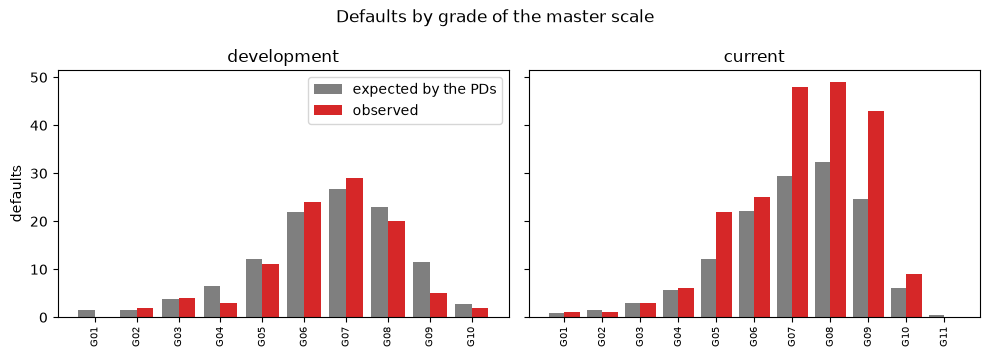

In [14]:
# Draw, for each grade of the master scale, the defaults the PDs expect and the defaults observed, for both samples
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, (pd_s, y_s)) in zip(axes, samples.items()):
    present = [g for g in grade_table(pd_s, y_s) if g["n"] > 0]
    positions = np.arange(len(present))
    expected = [g["pd"] * g["n"] for g in present]
    ax.bar(positions - 0.2, expected, width=0.4, label="expected by the PDs", color="tab:gray")
    ax.bar(positions + 0.2, [g["d"] for g in present], width=0.4, label="observed", color="tab:red")
    ax.set_xticks(positions)
    ax.set_xticklabels([g["grade"] for g in present], rotation=90, fontsize=7)
    ax.set_title(NAMES[name])
axes[0].set_ylabel("defaults")
axes[0].legend()
fig.suptitle("Defaults by grade of the master scale")
fig.tight_layout()
plt.show()

In each grade, the grey bar is the number of defaults the PDs expect and the red bar the defaults observed. On the development sample on the left the two bars track each other along all ten grades, with differences of a few defaults in either direction. On the current sample on the right the observed defaults exceed the expected ones in the middle and upper grades: 48 against about 29 in G07, 49 against 32 in G08 and 43 against 25 in G09, with G05 also well above. That is the pattern of a level that is too low, and it is the truth the sample was built with. The figure does not show that the excess is the same share in every grade; the tests treat the grades together.

### Step 10: a suite never stops at the first failure

A validator needs the whole picture, so a test that raises is recorded as a result in the state `error`, and the remaining tests still run. The next cell takes three tasks of the current battery, replaces the middle one with a Jeffreys test on a portfolio of zero obligors, which must fail, and runs the suite.

In [15]:
# Insert a task that must fail (the Jeffreys test on zero obligors) and show that the suite records it and finishes
current_tasks = batteries["current"]
broken = [current_tasks[0], (cal.pd_jeffreys, dict(n=0, d=0, pd=0.05)), current_tasks[3]]
mixed = run_suite(broken, policy=policy, model_id="current", segment="portfolio")
states = [{"test": r.test_id, "state": LIGHT[r.light.value]} for r in mixed.results]
print("worst light:", LIGHT[mixed.worst().value])
print("counts:", {LIGHT[key]: value for key, value in mixed.counts().items() if value})
pd.DataFrame(states)

worst light: error
counts: {'green': 1, 'not evaluated': 1, 'error': 1}


,test,state
0,disc.auc,not evaluated
1,pd.jeffreys,error
2,pd.binomial_vasicek,green


The suite finished all three tasks: the AUC is not evaluated, the Jeffreys test on zero obligors is recorded in the state `error`, and the Vasicek-adjusted binomial still ran and is green. The worst light is `error`, which is how a failing test announces itself in the summary instead of disappearing from it. The engine keeps the exception text in the result's notes for the validator to read. What the suite does not do is guess a value for the failed test; the gap stays a gap.

## Results

**Answer:** Yes. Under the default policy the battery leaves the calibrated development sample alone, with six green results and none red, and finds the current sample: six of its nine results are red, led by the PSI with a p-value of 4.21e-10, while the AUC of 0.779 is no lower than the development AUC of 0.743 and the AUC test against the initial one stays green.

- **Contract 1 rejected exactly what it should.** Of the five rows written by hand it rejected the PD of 1.2, the target `yes` and the repeated identifier, accepted the other two and listed the extra column as ignored. The two real files were accepted whole.
- **The level tests carry the finding.** The Jeffreys, binomial, Hosmer-Lemeshow and Spiegelhalter tests are all red with p-values below 1e-8, and the chi-square over grades is red at 2.65e-07. The figure by grade shows the cause: from G05 up, with G06 only slightly above, the observed defaults exceed what the PDs expect.
- **The ranking is intact.** A model can rank as well as at development and be mis-sized, which is why a battery has level tests as well as discrimination tests.
- **The Vasicek-adjusted binomial is green.** Its p-value is 0.114: allowing for a 0.04 correlation absorbs the excess, and here that is a miss. The price of allowing for correlation is power.
- **The PSI is red although its value, 0.0626, is inside the conventional 0.10 band.** The chi-square benchmark gives a critical PSI of 0.0169 at 5%, and with 2,000 obligors per sample it detects a shift the rule of thumb misses.
- **A failing test does not stop the suite.** It is recorded as `error` and the others run.

What the lights do not show: they are the default policy's reading and not a compliance verdict (notebook 03), and the samples are synthetic with a known truth, which real portfolios never have.

## Summary

- Contract 1 turns a CSV into accepted records and reports what it rejected, flagged or ignored; it never coerces a value.
- The master scale turns PDs into twelve grades, and the grade table is the input of the grade-level tests.
- `run_suite` runs a list of `(function, arguments)` tasks under one policy, records a failing test as an `error` result and finishes the battery.
- The level tests find the shifted sample and leave the calibrated one alone; the ranking test is not enough on its own; the PSI is read against a chi-square benchmark and not a rule of thumb.
- Each opened test has its own reference distribution and degrees of freedom, and the engine makes the assumptions (`fitted`, `rho`) explicit arguments.

**What to try next.** Put your own scored sample through the door the product ships for it (`data-pipeline/validate.py`, see `docs/guides/02_validate-your-own-model.md`) and compare its table with this one. Then read `docs/guides/03_read-a-validation-report.md`, and continue with topic 02, which builds the models that this battery validates.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial, the Vasicek-adjusted binomial and the chi-square over grades. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/guides/02_validate-your-own-model.md` and `docs/guides/03_read-a-validation-report.md`.